In [1]:
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
import pickle

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# Load preprocessed data
data = np.load("../models/preprocessed_data.npz")

X_train = data['X_train']
X_val = data['X_val']
X_test = data['X_test']

y_train = data['y_train']
y_val = data['y_val']
y_test = data['y_test']

# Load tokenizer
with open("../models/tokenizer.pkl", "rb") as file:
    tokenizer = pickle.load(file)

# Get vocabulary size and sequence length
vocab_size = len(tokenizer.word_index) + 1
max_length = X_train.shape[1]

print("Data loaded successfully!")
print("Training Shape:", X_train.shape)
print("Validation Shape:", X_val.shape)
print("Testing Shape:", X_test.shape)
print("Vocabulary Size:", vocab_size)
print("Maximum Sequence Length:", max_length)



Data loaded successfully!
Training Shape: (3721, 33)
Validation Shape: (414, 33)
Testing Shape: (1034, 33)
Vocabulary Size: 7197
Maximum Sequence Length: 33


In [2]:

model = Sequential([
    Embedding(
        input_dim=vocab_size,
        output_dim=64,
        mask_zero=True
    ),

    LSTM(64),

    Dropout(0.3),

    Dense(1, activation='sigmoid')
])

# Display model architecture
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [3]:

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

print("Model compiled successfully!")


Model compiled successfully!


In [4]:
from sklearn.utils.class_weight import compute_class_weight

classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight='balanced',
    classes=classes,
    y=y_train
)

class_weights = dict(zip(classes, weights))

print("Class Weights:", class_weights)

Class Weights: {np.int64(0): np.float64(0.5722854506305752), np.int64(1): np.float64(3.9585106382978723)}


In [5]:
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True,
    verbose=1
)

In [6]:
history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=15,
    batch_size=32,
    class_weight=class_weights,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/15
117/117 ━━━━━━━━━━━━━━━━━━━━ 13s 24ms/step - accuracy: 0.8361 - loss: 0.3364 - val_accuracy: 0.9686 - val_loss: 0.1520
Epoch 2/15
117/117 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - accuracy: 0.9871 - loss: 0.0869 - val_accuracy: 0.9710 - val_loss: 0.0986
Epoch 3/15
117/117 ━━━━━━━━━━━━━━━━━━━━ 3s 21ms/step - accuracy: 0.9954 - loss: 0.0359 - val_accuracy: 0.9614 - val_loss: 0.1145
Epoch 4/15
117/117 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - accuracy: 0.9984 - loss: 0.0192 - val_accuracy: 0.9758 - val_loss: 0.0976
Epoch 5/15
117/117 ━━━━━━━━━━━━━━━━━━━━ 3s 21ms/step - accuracy: 0.9984 - loss: 0.0098 - val_accuracy: 0.9710 - val_loss: 0.0967
Epoch 6/15
117/117 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - accuracy: 0.9909 - loss: 0.0357 - val_accuracy: 0.9686 - val_loss: 0.1152
Epoch 7/15
117/117 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - accuracy: 0.9965 - loss: 0.0276 - val_accuracy: 0.9686 - val_loss: 0.1016
Epoch 8/15
117/117 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - accuracy: 0.9981 - loss: 0.0105 - val_acc

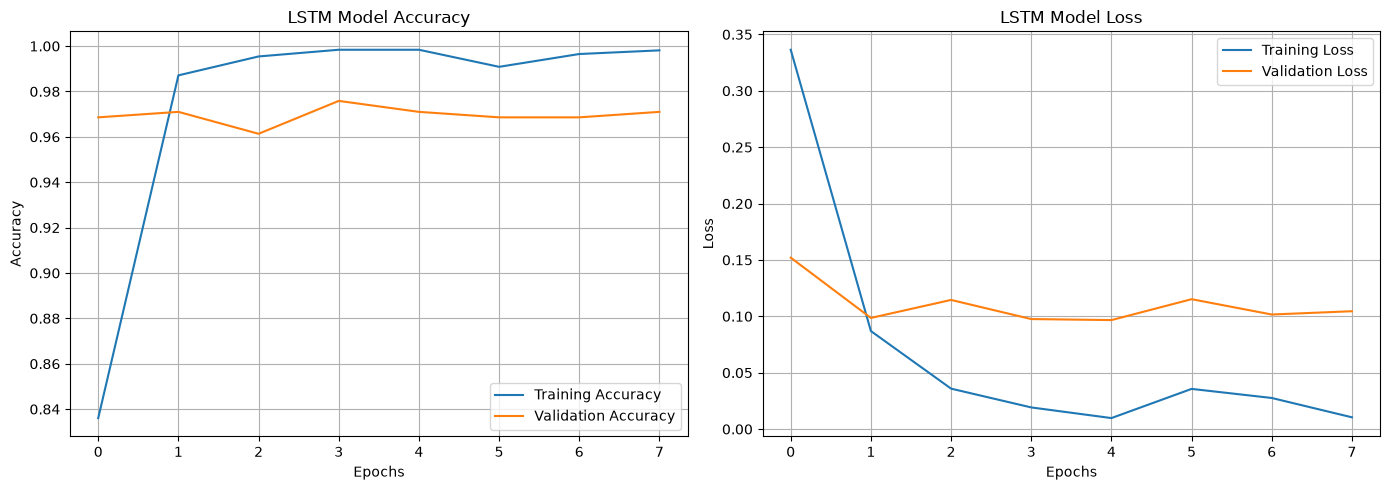

In [7]:

# Create accuracy and loss plots
plt.figure(figsize=(14, 5))

# Accuracy graph
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('LSTM Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# Loss graph
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('LSTM Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


In [8]:
model.save("../models/sms_spam_lstm.keras")

print("LSTM model saved successfully!")

LSTM model saved successfully!


In [9]:
import pickle
import os

os.makedirs("../models", exist_ok=True)

with open("../models/training_history.pkl", "wb") as file:
    pickle.dump(history.history, file)

print("Training history saved successfully!")

Training history saved successfully!


In [10]:
model.save("../models/sms_spam_lstm.keras")

print("LSTM model saved successfully!")

LSTM model saved successfully!
